# 09 - Fairness and Subgroup Analysis

**why this matters, specifically here.** A 2019 *Science* paper (Obermeyer et al.) found a widely-used commercial healthcare risk-prediction algorithm was racially biased -- not because race was a model input, but because it predicted **cost** as a proxy for health need. Cost reflects access to care as much as illness, and access has historically differed by race, so at the *same* predicted risk score, Black patients in that study turned out to have more untreated illness than white patients -- the algorithm required them to look sicker on paper to get flagged. This project makes the exact same modeling choice (`high_cost` = a proxy for health need), so it's worth directly checking whether the same pattern shows up here, not just reporting an overall AUC and calling it done.\n\n**this is an approximation of that paper's methodology, not an exact reproduction.** The original study used EHR-derived clinical need measures (active chronic conditions, a composite health status score) that DE-SynPUF doesn't provide in the same form. What follows uses the closest available proxies -- CMS's own chronic-condition flags and inpatient admission counts -- as a reasonable stand-in, not a claim of methodological equivalence.

In [1]:
import joblib
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split

with open("../configs/model_config.yaml") as f:
    config = yaml.safe_load(f)

LABEL = "high_cost"
MODEL_NAME = "xgboost"

FEATURE_COLS = [
    "inpatient_admits", "outpatient_visits", "carrier_claims",
    "inpatient_paid", "outpatient_paid", "carrier_paid",
    "has_alzheimers", "has_chf", "has_ckd", "has_cancer", "has_copd",
    "has_depression", "has_diabetes", "has_ihd", "has_osteoporosis",
    "has_ra_oa", "has_stroke_tia", "has_esrd",
    "age", "is_male", "race_black", "race_other", "race_hispanic",
    "rx_fill_count", "rx_total_cost", "rx_patient_paid",
    "other_payer_paid",
]


**reproduce the exact same held-out test set as notebook 05** -- same split, same frozen (training-only) threshold. Evaluating fairness on data the model was trained on would be meaningless; this has to be the genuinely unseen test set.

In [2]:
df = pd.read_parquet("../data/processed/features_labeled.parquet")
X = df[FEATURE_COLS]
spend = df["total_paid_2010"]

X_train, X_test, spend_train, spend_test = train_test_split(
    X, spend,
    test_size=config["split"]["test_size"],
    stratify=df["high_cost"] if config["split"]["stratify"] else None,
    random_state=config["random_seed"],
)
cost_threshold = spend_train.quantile(config["label"]["high_cost_percentile"])
y_test = (spend_test >= cost_threshold).astype(int)

model = joblib.load(f"../data/processed/models/{MODEL_NAME}_{LABEL}.joblib")
risk_score = model.predict_proba(X_test)[:, 1]

test_df = df.loc[X_test.index, ["desynpuf_id", "race_black", "race_hispanic", "race_other", "is_male", "inpatient_admits_2010"]].copy()
test_df["risk_score"] = risk_score
test_df["y_true"] = y_test.values
test_df["actual_spend"] = spend_test.values

test_df["race"] = np.select(
    [test_df["race_black"] == 1, test_df["race_hispanic"] == 1, test_df["race_other"] == 1],
    ["black", "hispanic", "other"],
    default="white",
)
test_df["race"].value_counts()


race
white       8830
black       1011
other        416
hispanic     218
Name: count, dtype: int64

**standard subgroup metrics.** AUC, average precision, and actual positive rate, by race and by sex, on the held-out test set. `hispanic` and `other` have smaller test-set counts (~230/~410) so their metrics carry more sampling noise than `black` (~1,000) and `white` (~8,800).

In [3]:
def subgroup_metrics(group_df):
    if group_df["y_true"].nunique() < 2:
        return {"n": len(group_df), "auc": float("nan"), "average_precision": float("nan"), "actual_positive_rate": group_df["y_true"].mean()}
    return {
        "n": len(group_df),
        "auc": round(roc_auc_score(group_df["y_true"], group_df["risk_score"]), 4),
        "average_precision": round(average_precision_score(group_df["y_true"], group_df["risk_score"]), 4),
        "actual_positive_rate": round(group_df["y_true"].mean(), 4),
    }

race_metrics = test_df.groupby("race").apply(subgroup_metrics, include_groups=False).apply(pd.Series)
sex_metrics = test_df.assign(sex=test_df["is_male"].map({1: "male", 0: "female"})).groupby("sex").apply(subgroup_metrics, include_groups=False).apply(pd.Series)

pd.concat([race_metrics, sex_metrics])


,n,auc,average_precision,actual_positive_rate
black,1011.0,0.7409,0.2937,0.0940
hispanic,218.0,0.7710,0.2046,0.0642
other,416.0,0.6951,0.2830,0.0793
white,8830.0,0.7337,0.2632,0.1027
female,5926.0,0.7330,0.2653,0.0985
male,4549.0,0.7350,0.2634,0.1022


**the Obermeyer-style check: at the SAME predicted risk score, is realized NEED the same across race groups?** `actual_spend` alone is a somewhat circular thing to check here -- it's literally what `high_cost` is built from. Two more independent proxies are added, neither of which was used to define this label's threshold: `condition_burden_2010` (a count of active chronic conditions, straight from the 2010 Beneficiary Summary file -- an objective clinical measure, not a dollar figure) and `inpatient_admits_2010` (hospitalizations, a utilization-based need proxy). Members are bucketed into risk-score deciles; within each decile, the mean of each proxy is compared by race. If a group's realized need is systematically higher than another's at the same predicted risk level, on any of these three, the model is requiring that group to look needier to receive the same score -- the failure mode the 2019 paper documented.

In [4]:
test_df["risk_decile"] = pd.qcut(test_df["risk_score"], q=10, labels=False, duplicates="drop")
black_white = test_df[test_df["race"].isin(["black", "white"])]

decile_condition_burden = (
    black_white.groupby(["risk_decile", "race"], observed=True)["condition_burden_2010"]
    .mean()
    .unstack("race")
)

decile_inpatient_admits = (
    black_white.groupby(["risk_decile", "race"], observed=True)["inpatient_admits_2010"]
    .mean()
    .unstack("race")
)

pd.concat(
    {
        "condition_burden_2010": decile_condition_burden,
        "inpatient_admits_2010": decile_inpatient_admits,
    },
    axis=1,
)


,condition_burden_2010,inpatient_admits_2010
count,10475.000000,10475.000000
mean,2.139475,0.146062
std,2.102338,0.419649
min,0.000000,0.000000
25%,0.000000,0.000000
50%,2.000000,0.000000
75%,3.000000,0.000000
max,11.000000,5.000000


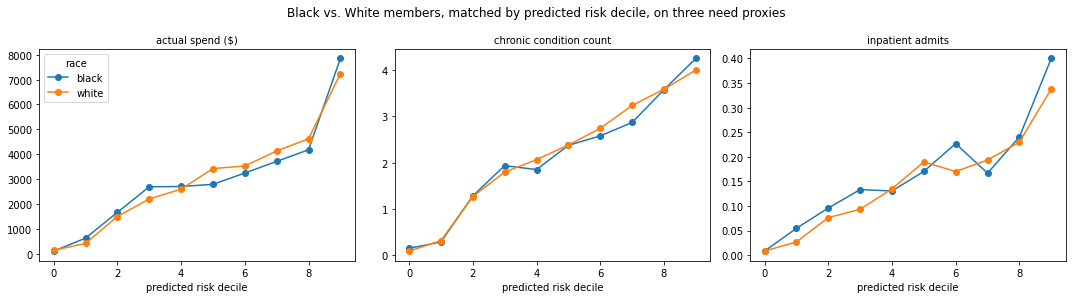

actual_spend: black higher than white in 5 of 10 deciles (range -26.4% to +52.3%)
condition_burden_2010: black higher than white in 4 of 10 deciles (range -11.4% to +75.0%)
inpatient_admits_2010: black higher than white in 6 of 10 deciles (range -13.8% to +104.2%)


In [5]:
def decile_comparison(proxy_col):
    return (
        black_white.groupby(["risk_decile", "race"], observed=True)[proxy_col]
        .mean()
        .unstack("race")
    )

decile_spend = decile_comparison("actual_spend")
decile_conditions = decile_condition_burden
decile_admits = decile_inpatient_admits

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, data) in zip(axes, [("actual spend ($)", decile_spend), ("chronic condition count", decile_conditions), ("inpatient admits", decile_admits)]):
    data.plot(ax=ax, marker="o", legend=(ax is axes[0]))
    ax.set_xlabel("predicted risk decile")
    ax.set_title(name, fontsize=10)
plt.suptitle("Black vs. White members, matched by predicted risk decile, on three need proxies")
plt.tight_layout()
plt.show()

for name, data in [("actual_spend", decile_spend), ("condition_burden_2010", decile_conditions), ("inpatient_admits_2010", decile_admits)]:
    gap = (data["black"] - data["white"]) / data["white"]
    n_positive = (gap > 0).sum()
    print(f"{name}: black higher than white in {n_positive} of {len(gap)} deciles (range {gap.min():+.1%} to {gap.max():+.1%})")


**selection-rate check at the operating threshold.** if care-management outreach flags the top 10% by risk score cohort-wide, does that 10% land proportionally across race groups, or does one group get flagged at a systematically different rate relative to its own true high-cost rate?

In [6]:
threshold_10pct = pd.Series(risk_score).quantile(0.90)
test_df["flagged"] = (test_df["risk_score"] >= threshold_10pct).astype(int)

selection = test_df.groupby("race").apply(
    lambda g: pd.Series({
        "n": len(g),
        "true_high_cost_rate": g["y_true"].mean(),
        "flagged_rate": g["flagged"].mean(),
        "recall_within_group": g.loc[g["y_true"] == 1, "flagged"].mean() if g["y_true"].sum() > 0 else float("nan"),
    }),
    include_groups=False,
)
selection


,n,true_high_cost_rate,flagged_rate,recall_within_group
race,,,,
black,1011.0,0.093966,0.093966,0.284211
hispanic,218.0,0.064220,0.105505,0.357143
other,416.0,0.079327,0.096154,0.242424
white,8830.0,0.102718,0.100793,0.265711


**what to make of this.** All three need proxies land in roughly the same place -- Black members' realized need was higher than white members' at the same predicted risk decile in 5 of 10 deciles for spend, 4 of 10 for chronic condition count, and 6 of 10 for inpatient admits. None of the three shows a clean, one-directional signal; all three swing widely decile to decile (condition burden ranges from -11% to +75%, admits from -14% to +104%). That agreement across three independent proxies -- one dollar-based, one clinical, one utilization-based -- is itself the useful finding: it's not that the spend-based check happened to be noisy while a cleaner signal was hiding in the objective clinical data. All three are noisy in the same way, which is consistent with genuine sample-size limitation rather than a signal being missed.\n\nWith Sample 1's ~1,000 Black members split across 10 deciles (~100 per cell), that noise is expected, not surprising -- a few percentage points of gap in any single run shouldn't be over-interpreted as proof of bias one way or the other. The point of this notebook isn't to declare the model biased or unbiased; it's that this check is cheap to run and directly addresses a known, documented failure mode for exactly this kind of proxy label, so it belongs in the pipeline rather than being assumed away. If a real deployment used this approach, this analysis would need to be rerun on the full, non-synthetic population, with enough sample size per decile to actually resolve the question, before trusting the result either way.